rumz
# Notebook for processing bubbles in Ice Cores
### Updated Sept 25
#### V. 3.1
- updated to match file processing updates: 1.3
- Used adaptive thresholding: 2.2
- updated with better bubble detection: 3.1

This notebook processes hyperspectral images of ice and extracts information in regards to the bubbles.
To run:
- ensure datasetPath points to the correct directory file
- Insert DataID for whichever core to be run

In [1]:
# Importing Python Libraries
import warnings
import sys
import os
import matplotlib as plt

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from Sums import sums_process_module as processSums
from icespec import savePNG
from icespec import ageConversion

In [2]:
DataID = "HSIUM-35" #insert DataID from excel file inside quotation marks

## This should be its own function ##
NumID = int(DataID.split('-')[-1])
if NumID <= 228:
    datasetPath = '/data/icecores/HSI_2024.csv'
elif 229 <= NumID < 335:
    datasetPath = '/data/icecores/HSI_2023_1.csv'
elif 335 <= NumID < 363:
    datasetPath = '/data/icecores/HSI_June2025.csv'
elif 363 <= NumID < 586:
    datasetPath = '/data/icecores/HSI_Sept2025.csv'
elif 586 <= NumID < 774:
    datasetPath = '/data/icecores/HSI_Denali2025.csv'
elif 774 <= NumID < 896:
    datasetPath = '/data/icecores/HSI_Jan2024.csv'
elif 896 <= NumID < 899:
    datasetPath = '/data/icecores/HSI_2024.csv'
else:
    raise ValueError(f"NumID {NumID} is outside supported ranges (<=228, 229–334, 335–362, 363–585, 586–750, 751–872). \n Please check DataID and try again.")
    

outputDir = '/data/icecores/Output' #png output path
SCRIPT_ID = "BubblesNB"

Debug = True

In [3]:
dataPath, top_depth, bottom_depth, core_length, save_path, px_dims, metadata = processice.getDataPath(datasetPath, DataID, outputDir)

# bottom_depth = 162.455

outputPath = processice.make_dir(save_path, SCRIPT_ID, metadata)
print("Output Path: ", outputPath)

data_nparr, w_ref, d_ref, wvls, fwhm = processice.getEnviData(dataPath)

Core:  ALHIC 1901
Section:  228_4-LA1
Lighting: Top light - 50%, Bottom Light - 100%
Exposure:  10
Top Depth:  155.07
Bottom Depth:  155.14
Length =  0.06999999999999318
Dimensions:  1165, 1530, 440, 590
Data Path:  July2024/ALHIC1901-228_4_0002_HSI_UM_Jul24
Output Path:  /data/icecores/Output/AN/ALHIC/ALHIC1901/ALHIC1901-228_4-LA1/2026-03-27_143419
<class 'numpy.ndarray'>


In [4]:
segment_boundaries, pixels_per_cm = processbubbles.get_segments(data_nparr, top_depth, bottom_depth, start_px=px_dims[0], end_px=px_dims[1])
print("pixels per cm: ", pixels_per_cm)

core bottom depth: 155.14 - core top depth: 155.07 = core length: 0.06999999999999318
core length cm: 6.999999999999318
end px: 1530 - start px: 1165 = total px height: 365
ice height px: 365 / core length cm: 6.999999999999318 = px per cm: 52.142857142862226
standard px height: 325 / standard length: 5.08 = px per cm: 63.976377952755904
pixels per cm:  63.976377952755904


In [5]:
#dataSize = [1500, 6600, 200, 900] #fill in based on interactive plot
px_dims = [px_dims[0] + 10, px_dims[1], px_dims[2], px_dims[3]]
dataSize = px_dims ## Need NaN Handling
stdSize = [530, 820, 200, 900] #standard sizing

The new dimensions will be: 150x355
Trimmed shapes: (355, 150, 224), W_ref: (175, 150, 224), D_ref: (100, 150, 224)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Reflectance calculated. Dimensions: (355, 150, 224)


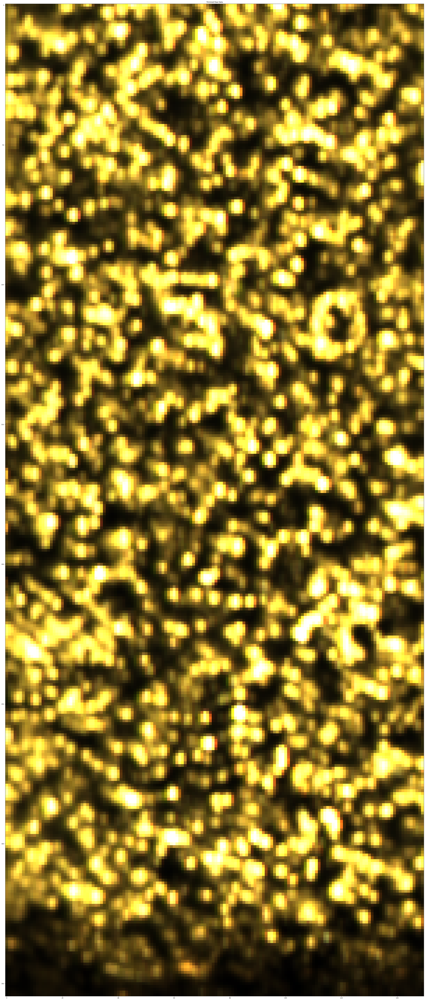

In [6]:
trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize, Debug=Debug) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)

In [7]:
print("WVs: ", wvls)

WVs:  [ 397.66  400.28  402.9   405.52  408.13  410.75  413.37  416.    418.62
  421.24  423.86  426.49  429.12  431.74  434.37  437.    439.63  442.26
  444.89  447.52  450.16  452.79  455.43  458.06  460.7   463.34  465.98
  468.62  471.26  473.9   476.54  479.18  481.83  484.47  487.12  489.77
  492.42  495.07  497.72  500.37  503.02  505.67  508.32  510.98  513.63
  516.29  518.95  521.61  524.27  526.93  529.59  532.25  534.91  537.57
  540.24  542.91  545.57  548.24  550.91  553.58  556.25  558.92  561.59
  564.26  566.94  569.61  572.29  574.96  577.64  580.32  583.    585.68
  588.36  591.04  593.73  596.41  599.1   601.78  604.47  607.16  609.85
  612.53  615.23  617.92  620.61  623.3   626.    628.69  631.39  634.08
  636.78  639.48  642.18  644.88  647.58  650.29  652.99  655.69  658.4
  661.1   663.81  666.52  669.23  671.94  674.65  677.36  680.07  682.79
  685.5   688.22  690.93  693.65  696.37  699.09  701.81  704.53  707.25
  709.97  712.7   715.42  718.15  720.87  723.

In [8]:
img_short = correctedData[:, :, 0:3]      #400nm
fwhm_short = fwhm[0:3]

img_mid = correctedData[:, :, 110:113]    #~650nm
fwhm_mid = fwhm[110:113]

img_long = correctedData[:, :, 221:224]   #1000nm
fwhm_long = fwhm[221:224]


Found 633 initial markers in 0 band

Found 668 initial markers in 1 band

Found 686 initial markers in 2 band

Found 633 initial markers in 0 band

Found 668 initial markers in 1 band

Found 686 initial markers in 2 band
      Bubble_ID Bands  Num_Bands
0             2   [1]          1
1             3   [1]          1
2             5   [1]          1
3             6   [1]          1
4             8   [1]          1
...         ...   ...        ...
1623       1983   [3]          1
1624       1984   [1]          1
1625       1985   [3]          1
1626       1986   [3]          1
1627       1987   [3]          1

[1628 rows x 3 columns]
arr: type=ndarray, shape=(355, 150, 3), ndim=3, dtype=float64


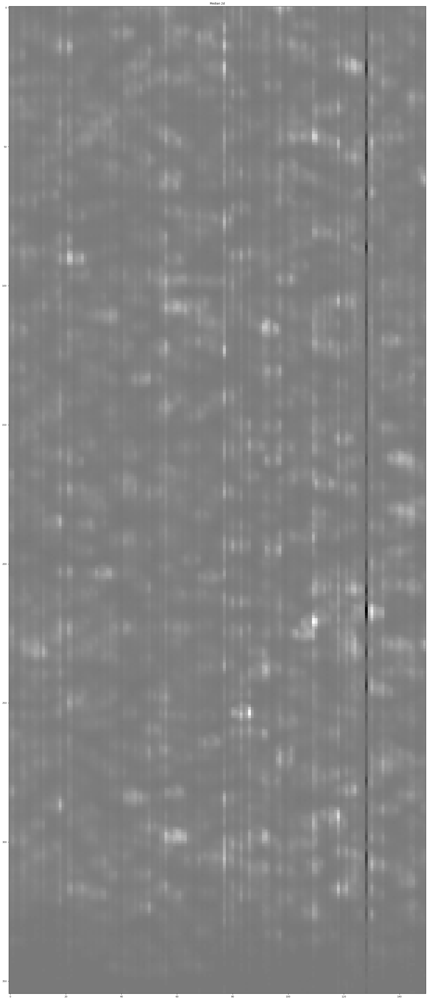

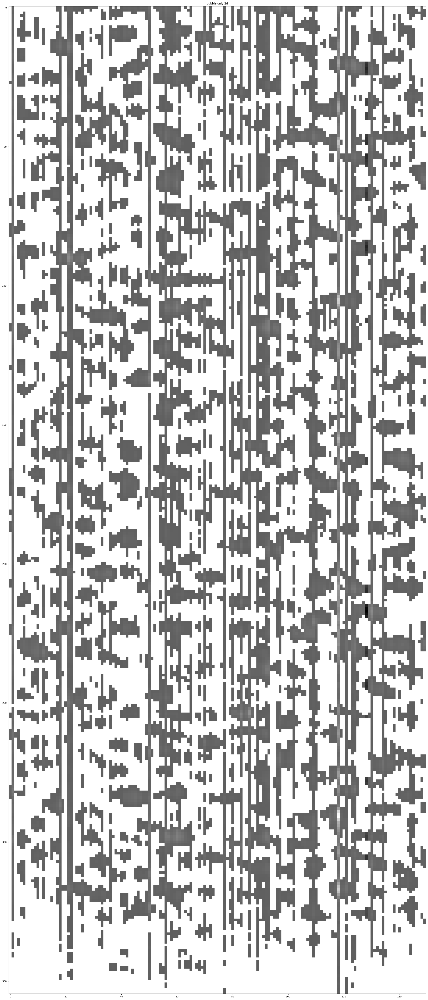

Median 2D shape: (355, 150); Valid Median 2D shape: (355, 150)
Global Median Radiance (from median_2d): 75.56124496459961
(2162, 2)
Found 2088 initial markers in median_2d
Markers stats: mean=42.59, max=2088, min=0, std=240.05


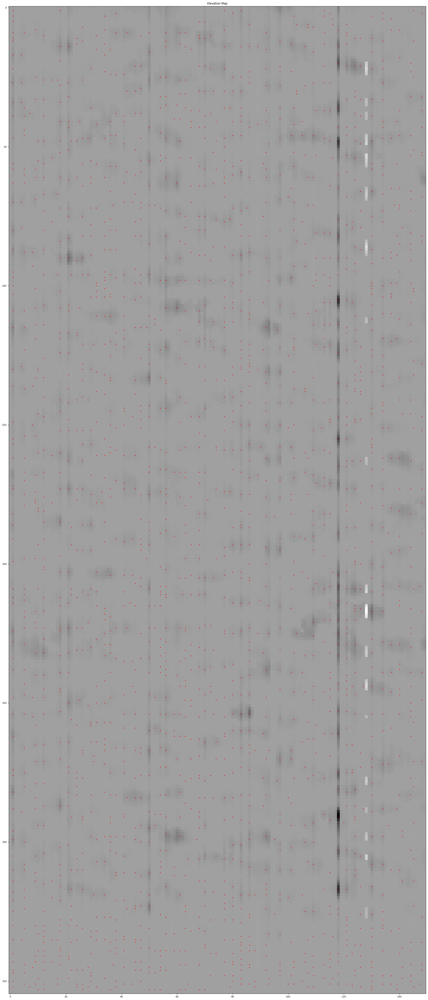

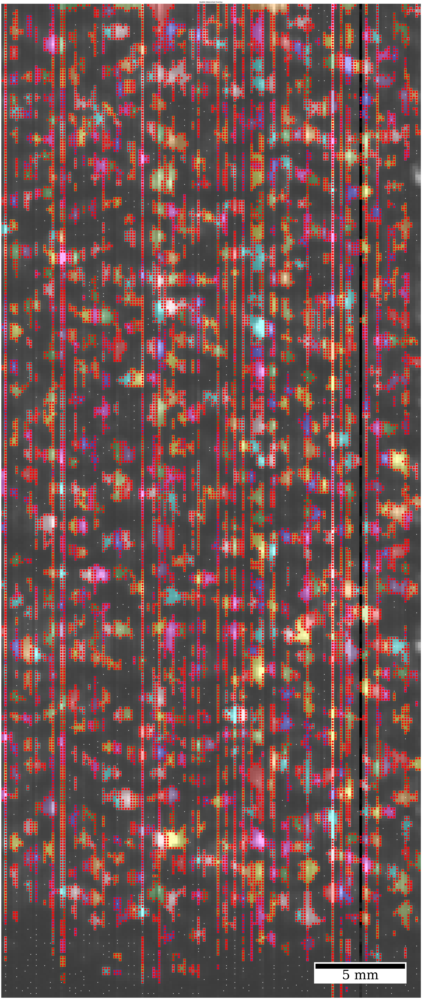

Top Depth = 155.07m
Crop Start Px = 1175
Px Per cm = 63.976377952755904
Minimum bubble size: 0.733
Maximum bubble size: 2.0767
Bubble Count: 80
Bubble 1:
  Area: 0.8063
  Centroid: (np.float64(4.0), np.float64(108.0))
  Orientation: -14.29 radians
  Elongation: 2.01
  Bounding Box: [0, 105, 10, 111]
Bubble 2:
  Area: 0.9773
  Centroid: (np.float64(9.0), np.float64(142.0))
  Orientation: 25.95 radians
  Elongation: 2.06
  Bounding Box: [3, 140, 16, 146]
Bubble 3:
  Area: 0.7818
  Centroid: (np.float64(10.0), np.float64(42.0))
  Orientation: -74.72 radians
  Elongation: 1.06
  Bounding Box: [7, 40, 13, 46]
Bubble 4:
  Area: 0.8796
  Centroid: (np.float64(2.0), np.float64(47.0))
  Orientation: 55.75 radians
  Elongation: 1.96
  Bounding Box: [0, 40, 11, 51]
Bubble 5:
  Area: 1.4171
  Centroid: (np.float64(4.0), np.float64(56.0))
  Orientation: -8.08 radians
  Elongation: 1.63
  Bounding Box: [0, 52, 11, 62]
Bubble 6:
  Area: 1.1239
  Centroid: (np.float64(10.0), np.float64(61.0))
  Orient

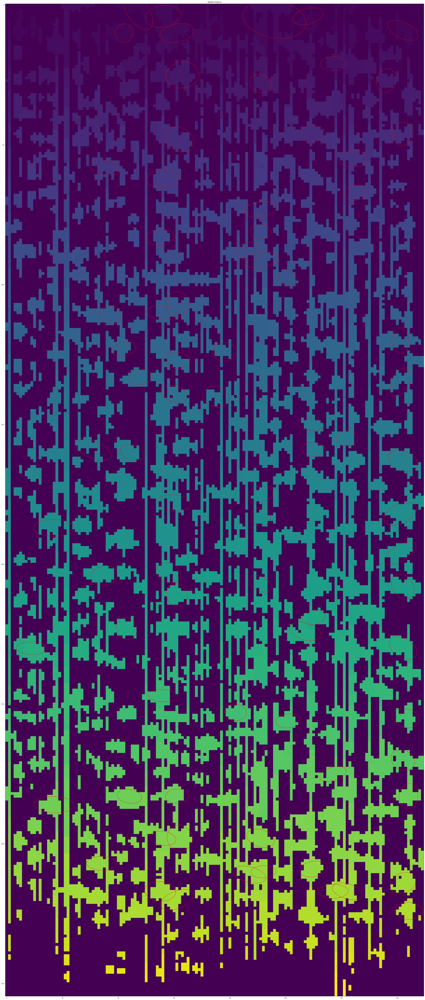

crop_start_px: 1175
crop_end_px: 1530
crop_end_px: 1530
original_start_px: 2470
pixels_per_cm: 63.976377952755904
top_depth_m: 155.07


In [9]:
bubbles_only_short, bubble_masks_short, bubble_only_2d_short, bubble_channel_map_short = processbubbles.get_bubbles(img_short, fwhm_short, clean=False, debug=Debug)

df_map_short = pd.DataFrame([
    {"Bubble_ID": b_id, "Bands": bands, "Num_Bands": len(bands)}
    for b_id, bands in bubble_channel_map_short.items()
])
print(df_map_short)
# Output df

print(f"arr: type={type(img_short).__name__}, shape={getattr(img_short,'shape',None)}, ndim={getattr(img_short,'ndim',None)}, dtype={getattr(img_short,'dtype',None)}")

segmented_img_short, x_coords_short, y_coords_short = processbubbles.rad_watershed(img_short, bubble_only_2d_short)
watershed_boundaries_short, watershed_boundary_pixels_short = processbubbles.getBoundaries(segmented_img_short, x_coords_short, y_coords_short, img_short, Save=False, savepath=outputPath)

analyzed_bubbles_short, bubble_df_short, bubble_area_ratio_short = processbubbles.analyze_bubbles(segmented_img_short, dataSize[0], pixels_per_cm, top_depth, min_size=30, Debug=Debug, Save=False, savepath=outputPath)
stats_df_short = processbubbles.get_stats(bubble_df_short, pixels_per_cm)
df_bubbles_per_cm_short = processbubbles.process_bubbles_per_cm(img_short, analyzed_bubbles_short, segment_boundaries, dataSize[0], dataSize[1], 2470, pixels_per_cm, top_depth)


Found 652 initial markers in 0 band

Found 639 initial markers in 1 band

Found 643 initial markers in 2 band

Found 652 initial markers in 0 band

Found 639 initial markers in 1 band

Found 643 initial markers in 2 band
      Bubble_ID   Bands  Num_Bands
0             4     [1]          1
1             6     [1]          1
2            16     [1]          1
3            17     [1]          1
4            18     [1]          1
...         ...     ...        ...
1182       1930  [1, 3]          2
1183       1931  [1, 2]          2
1184       1932     [1]          1
1185       1933     [1]          1
1186       1934     [1]          1

[1187 rows x 3 columns]
arr: type=ndarray, shape=(355, 150, 3), ndim=3, dtype=float64


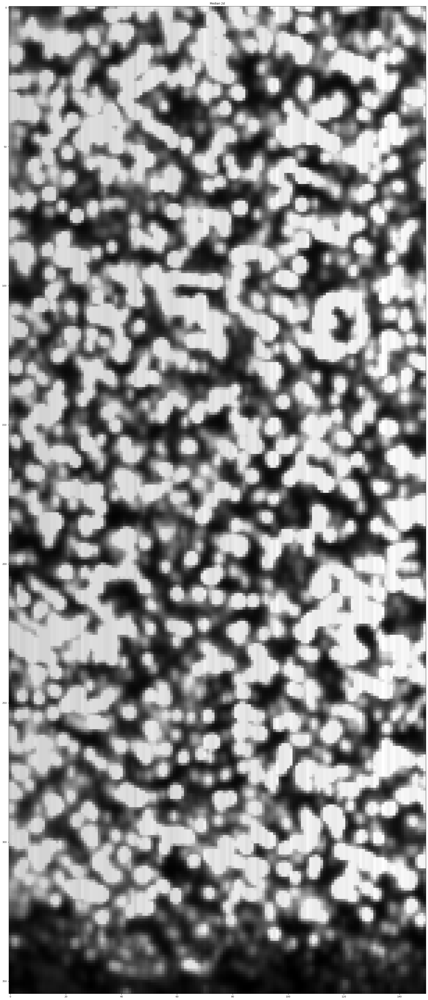

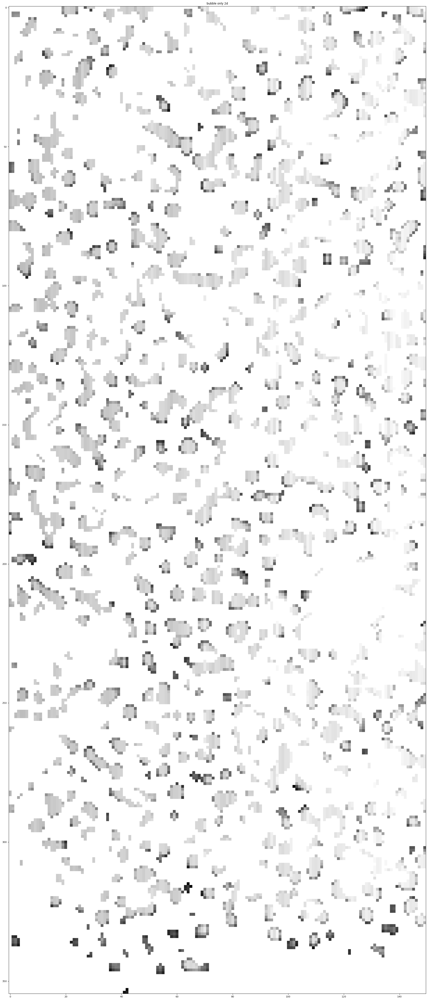

Median 2D shape: (355, 150); Valid Median 2D shape: (355, 150)
Global Median Radiance (from median_2d): 53.580543518066406
(4950, 2)
Found 1362 initial markers in median_2d
Markers stats: mean=59.72, max=1362, min=0, std=218.47


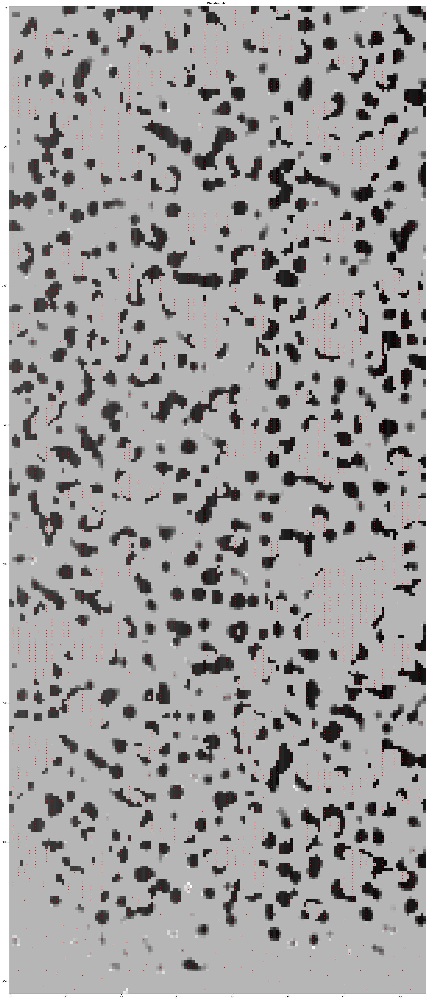

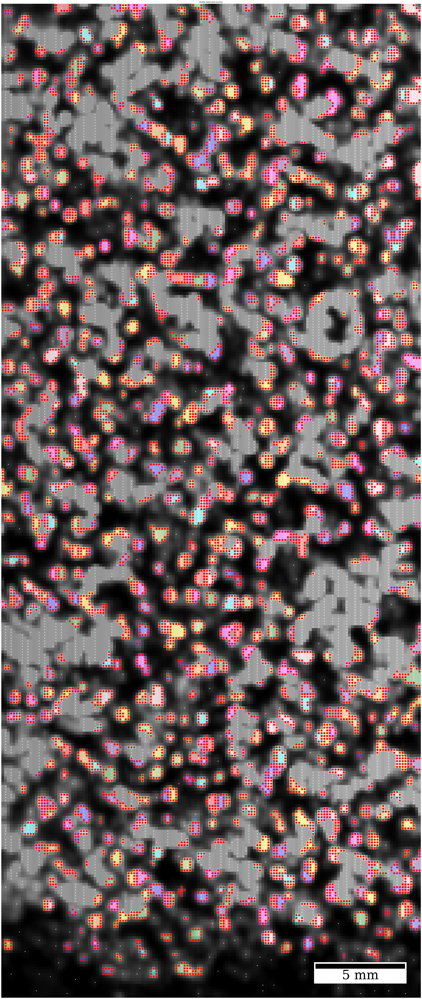

Top Depth = 155.07m
Crop Start Px = 1175
Px Per cm = 63.976377952755904
Minimum bubble size: 0.733
Maximum bubble size: 1.0017
Bubble Count: 16
Bubble 1:
  Area: 0.8307
  Centroid: (np.float64(29.0), np.float64(107.0))
  Orientation: -3.4 radians
  Elongation: 2.09
  Bounding Box: [25, 104, 34, 110]
Bubble 2:
  Area: 0.9284
  Centroid: (np.float64(31.0), np.float64(147.0))
  Orientation: -12.21 radians
  Elongation: 2.23
  Bounding Box: [26, 145, 36, 150]
Bubble 3:
  Area: 0.9529
  Centroid: (np.float64(34.0), np.float64(118.0))
  Orientation: -2.18 radians
  Elongation: 1.83
  Bounding Box: [30, 116, 40, 122]
Bubble 4:
  Area: 0.7574
  Centroid: (np.float64(55.0), np.float64(70.0))
  Orientation: -53.86 radians
  Elongation: 1.22
  Bounding Box: [52, 68, 59, 74]
Bubble 5:
  Area: 0.733
  Centroid: (np.float64(84.0), np.float64(54.0))
  Orientation: -7.94 radians
  Elongation: 2.15
  Bounding Box: [80, 53, 89, 58]
Bubble 6:
  Area: 0.8551
  Centroid: (np.float64(98.0), np.float64(101.0

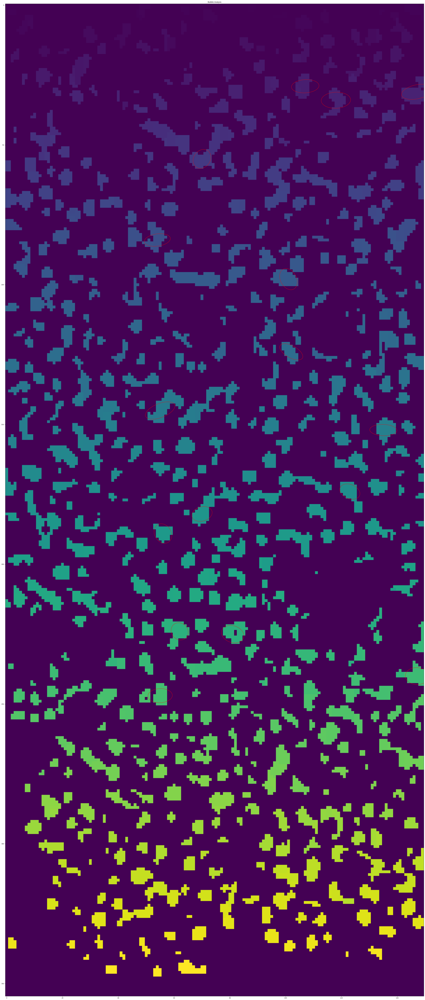

crop_start_px: 1175
crop_end_px: 1530
crop_end_px: 1530
original_start_px: 2470
pixels_per_cm: 63.976377952755904
top_depth_m: 155.07


In [10]:
bubbles_only_mid, bubble_masks_mid, bubble_only_2d_mid, bubble_channel_map_mid = processbubbles.get_bubbles(img_mid, fwhm_mid, clean=False, debug=Debug)

df_map_mid = pd.DataFrame([
    {"Bubble_ID": b_id, "Bands": bands, "Num_Bands": len(bands)}
    for b_id, bands in bubble_channel_map_mid.items()
])
print(df_map_mid)
# Output df

print(f"arr: type={type(img_mid).__name__}, shape={getattr(img_mid,'shape',None)}, ndim={getattr(img_mid,'ndim',None)}, dtype={getattr(img_mid,'dtype',None)}")

segmented_img_mid, x_coords_mid, y_coords_mid = processbubbles.rad_watershed(img_mid, bubble_only_2d_mid)
watershed_boundaries_mid, watershed_boundary_pixels_mid = processbubbles.getBoundaries(segmented_img_mid, x_coords_mid, y_coords_mid, img_mid, Save=False, savepath=outputPath)

analyzed_bubbles_mid, bubble_df_mid, bubble_area_ratio_mid = processbubbles.analyze_bubbles(segmented_img_mid, dataSize[0], pixels_per_cm, top_depth, min_size=30, Debug=Debug, Save=False, savepath=outputPath)
stats_df_mid = processbubbles.get_stats(bubble_df_mid, pixels_per_cm)
df_bubbles_per_cm_mid = processbubbles.process_bubbles_per_cm(img_mid, analyzed_bubbles_mid, segment_boundaries, dataSize[0], dataSize[1], 2470, pixels_per_cm, top_depth)


Found 451 initial markers in 0 band

Found 473 initial markers in 1 band

Found 472 initial markers in 2 band

Found 451 initial markers in 0 band

Found 473 initial markers in 1 band

Found 472 initial markers in 2 band
     Bubble_ID      Bands  Num_Bands
0            1        [1]          1
1            2        [1]          1
2            3        [1]          1
3            4        [1]          1
4            6        [1]          1
..         ...        ...        ...
806       1392        [2]          1
807       1393  [1, 2, 3]          3
808       1394     [1, 2]          2
809       1395     [1, 2]          2
810       1396        [2]          1

[811 rows x 3 columns]
arr: type=ndarray, shape=(355, 150, 3), ndim=3, dtype=float64


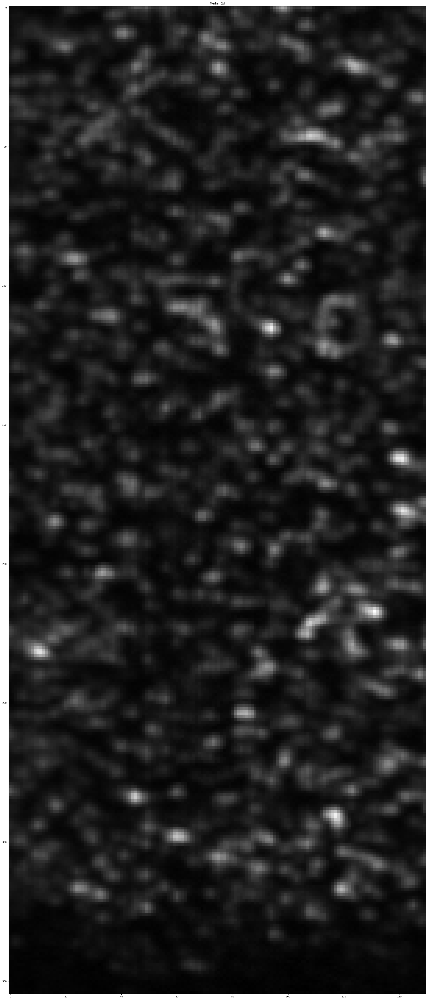

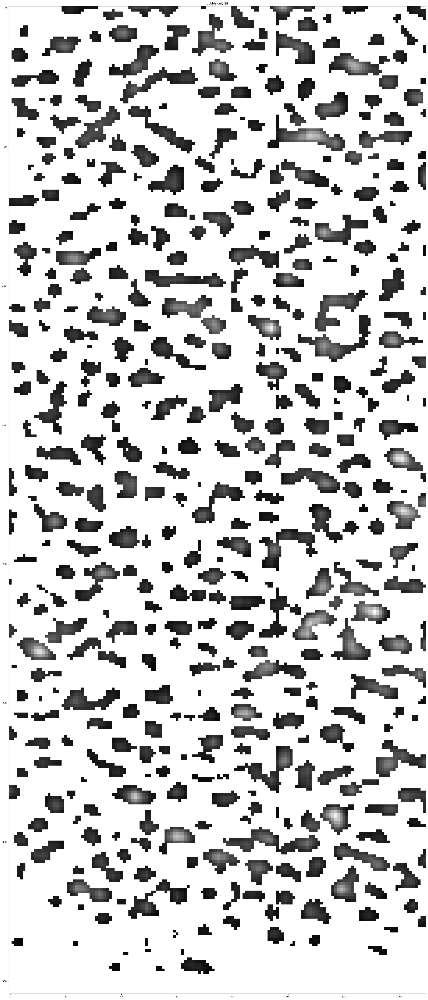

Median 2D shape: (355, 150); Valid Median 2D shape: (355, 150)
Global Median Radiance (from median_2d): 10.010479927062988
(1026, 2)
Found 1008 initial markers in median_2d
Markers stats: mean=9.68, max=1008, min=0, std=80.03


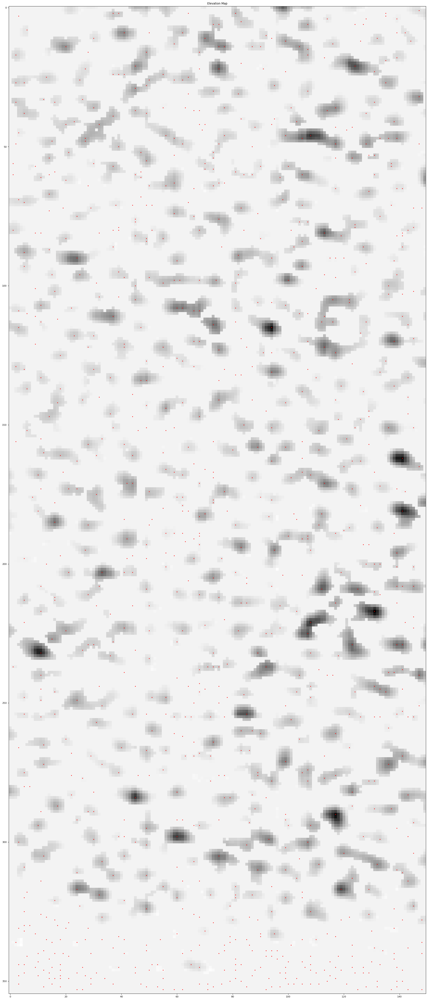

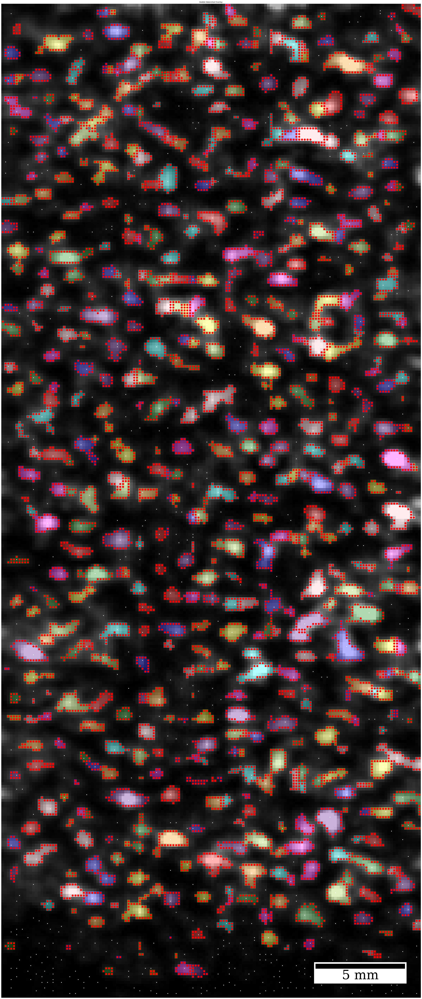

Top Depth = 155.07m
Crop Start Px = 1175
Px Per cm = 63.976377952755904
Minimum bubble size: 0.733
Maximum bubble size: 2.1012
Bubble Count: 138
Bubble 1:
  Area: 0.733
  Centroid: (np.float64(6.0), np.float64(107.0))
  Orientation: 85.92 radians
  Elongation: 1.45
  Bounding Box: [4, 104, 9, 111]
Bubble 2:
  Area: 1.1727
  Centroid: (np.float64(10.0), np.float64(41.0))
  Orientation: -89.74 radians
  Elongation: 1.7
  Bounding Box: [7, 36, 13, 46]
Bubble 3:
  Area: 0.8307
  Centroid: (np.float64(9.0), np.float64(60.0))
  Orientation: -65.74 radians
  Elongation: 1.41
  Bounding Box: [7, 57, 13, 65]
Bubble 4:
  Area: 0.904
  Centroid: (np.float64(11.0), np.float64(70.0))
  Orientation: -28.89 radians
  Elongation: 1.31
  Bounding Box: [8, 68, 16, 74]
Bubble 5:
  Area: 1.4659
  Centroid: (np.float64(14.0), np.float64(19.0))
  Orientation: -74.47 radians
  Elongation: 2.12
  Bounding Box: [11, 12, 18, 26]
Bubble 6:
  Area: 1.0017
  Centroid: (np.float64(15.0), np.float64(104.0))
  Orient

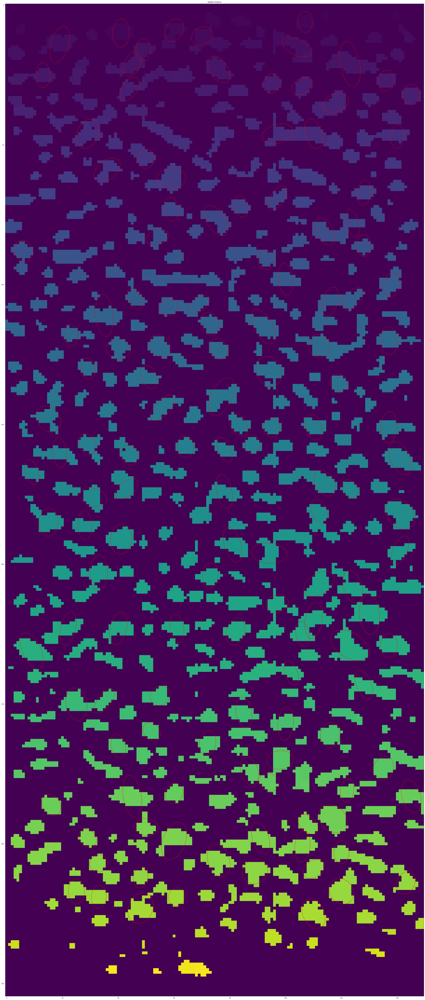

crop_start_px: 1175
crop_end_px: 1530
crop_end_px: 1530
original_start_px: 2470
pixels_per_cm: 63.976377952755904
top_depth_m: 155.07


In [11]:
bubbles_only_long, bubble_masks_long, bubble_only_2d_long, bubble_channel_map_long = processbubbles.get_bubbles(img_long, fwhm_long, clean=False, debug=Debug)

df_map_long = pd.DataFrame([
    {"Bubble_ID": b_id, "Bands": bands, "Num_Bands": len(bands)}
    for b_id, bands in bubble_channel_map_long.items()
])
print(df_map_long)
# Output df

print(f"arr: type={type(img_long).__name__}, shape={getattr(img_long,'shape',None)}, ndim={getattr(img_long,'ndim',None)}, dtype={getattr(img_long,'dtype',None)}")

segmented_img_long, x_coords_long, y_coords_long = processbubbles.rad_watershed(img_long, bubble_only_2d_long)
watershed_boundaries_long, watershed_boundary_pixels_long = processbubbles.getBoundaries(segmented_img_long, x_coords_long, y_coords_long, img_long, Save=False, savepath=outputPath)

analyzed_bubbles_long, bubble_df_long, bubble_area_ratio_long = processbubbles.analyze_bubbles(segmented_img_long, dataSize[0], pixels_per_cm, top_depth, min_size=30, Debug=Debug, Save=False, savepath=outputPath)
stats_df_long = processbubbles.get_stats(bubble_df_long, pixels_per_cm)
df_bubbles_per_cm_long = processbubbles.process_bubbles_per_cm(img_long, analyzed_bubbles_long, segment_boundaries, dataSize[0], dataSize[1], 2470, pixels_per_cm, top_depth)


In [12]:
print(df_bubbles_per_cm_short)

Empty DataFrame
Columns: [Depth_cm, Bubble_Count, Normalized_Count, Bubble_Number_Density, Avg_Bubble_Size, Bubble_Area_Ratio, Avg_Elongation, Avg_Eccentricity, Avg_Orientation, STD_Bubble_Size, STD_Elongation, STD_Eccentricity, STD_Orientation, Median_Bubble_Size, Median_Elongation, Median_Eccentricity, Median_Orientation, Median5_Bubble_Size, Median5_Elongation, Median5_Eccentricity, Median5_Orientation, Median95_Bubble_Size, Median95_Elongation, Median95_Eccentricity, Median95_Orientation, Trimmed_Mean_Bubble_Size, Trimmed_Mean_Elongation, Trimmed_Mean_Eccentricity, Trimmed_Mean_Orientation]
Index: []

[0 rows x 29 columns]


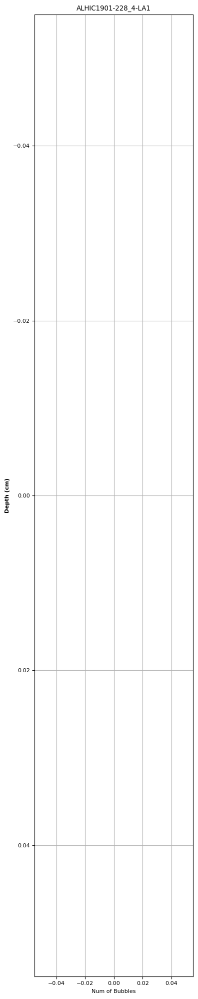

In [13]:
processbubbles.graph_bubble_stats(df_bubbles_per_cm_short, save=False, savepath=outputPath)

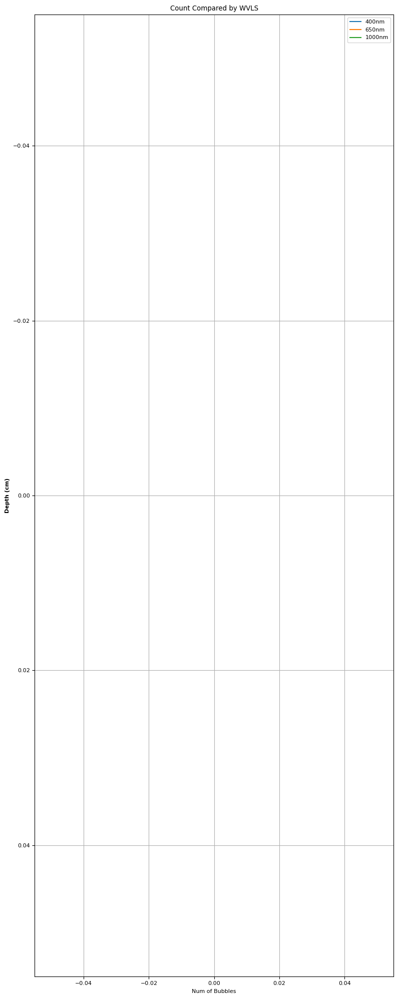

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 20))
plt.plot(df_bubbles_per_cm_short['Bubble_Count'], df_bubbles_per_cm_short['Depth_cm'], color='tab:blue', label='400nm')
plt.plot(df_bubbles_per_cm_mid['Bubble_Count'], df_bubbles_per_cm_mid['Depth_cm'], color='tab:orange', label='650nm')
plt.plot(df_bubbles_per_cm_long['Bubble_Count'], df_bubbles_per_cm_long['Depth_cm'], color='tab:green', label='1000nm')
plt.title(f"Count Compared by WVLS")
plt.ylabel("Depth (cm)", fontweight='bold')
plt.xlabel('Num of Bubbles')
plt.gca().invert_yaxis()  # invert y-axis
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import distance

# 1. Extract centroids and areas into numpy arrays for speed
coords_short = np.array([b['centroid'] for b in analyzed_bubbles_short])
areas_short = np.array([b['area'] for b in analyzed_bubbles_short])

coords_long = np.array([b['centroid'] for b in analyzed_bubbles_long])
areas_long = np.array([b['area'] for b in analyzed_bubbles_long])

# 2. Match bubbles using distance
# For each bubble in 'short', find the index of the closest one in 'long'
dist_matrix = distance.cdist(coords_short, coords_long)
closest_indices = np.argmin(dist_matrix, axis=1)
min_distances = np.min(dist_matrix, axis=1)

# tolerance (pixels) - if further than this, it's not the same bubble
tolerance = 5.0 

# 3. Compare and assign colors
colors = []
plot_coords = []
plot_sizes = []

for i, long_idx in enumerate(closest_indices):
    if min_distances[i] < tolerance:
        a_short = areas_short[i]
        a_long = areas_long[long_idx]
        
        # "No Change" within 5% of each other
        if abs(a_long - a_short) / a_short < 0.05:
            colors.append('orange')
        elif a_long > a_short:
            colors.append('red')
        else:
            colors.append('yellow')
            
        plot_coords.append(coords_short[i])
        plot_sizes.append(a_short)

plot_coords = np.array(plot_coords)

In [16]:
import numpy as np
from skimage import color

change_map = np.zeros_like(segmented_img_short, dtype=np.int32)

for i, long_idx in enumerate(closest_indices):
    if min_distances[i] < tolerance:
        # centroid coordinates (row, col)
        y, x = analyzed_bubbles_short[i]['centroid']

        label_id = segmented_img_short[int(y), int(x)]
        
        if label_id == 0:
            continue 

        a_short = areas_short[i]
        a_long = areas_long[long_idx]
        diff = (a_long - a_short) / a_short
        
        if abs(diff) < 0.05:
            cat_id = 2 # Orange
        elif diff > 0:
            cat_id = 3 # Red
        else:
            cat_id = 1 # Yellow
            
        change_map[segmented_img_short == label_id] = cat_id

In [17]:
# # colors: [Yellow, Orange, Red]
# custom_colors = [(1, 1, 0), (1, 0.6, 0), (1, 0, 0)]

# def to01(a, lo=None, hi=None):
#     if lo is None or hi is None:
#         lo, hi = np.nanpercentile(a, (1, 99))
#         if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
#             lo, hi = np.nanmin(a), np.nanmax(a)
#     a = np.nan_to_num(a, nan=lo)
#     out = (a - lo) / (hi - lo) if hi > lo else np.zeros_like(a, dtype=np.float32)
#     return np.clip(out, 0, 1).astype(np.float32)

# global_lo, global_hi = np.nanpercentile(correctedData, (1, 99))
# n = correctedData.shape[2]
# mid = n // 2
# base = to01(correctedData[:, :, mid], global_lo, global_hi)

# overlay = color.label2rgb(
#     change_map, 
#     image=base, 
#     colors=custom_colors,
#     bg_label=0,
#     alpha=0.4,
#     kind='overlay'
# )


# plt.figure(figsize=(20, 40))
# plt.imshow(overlay)
# plt.axis('off')
# out_path = f"{outputPath}/3dBubbles.png"
# plt.savefig(out_path, dpi=300, bbox_inches="tight")
# plt.title("Spatial Map of Bubble Size Change (.4µm vs 1µm)")
# plt.show()

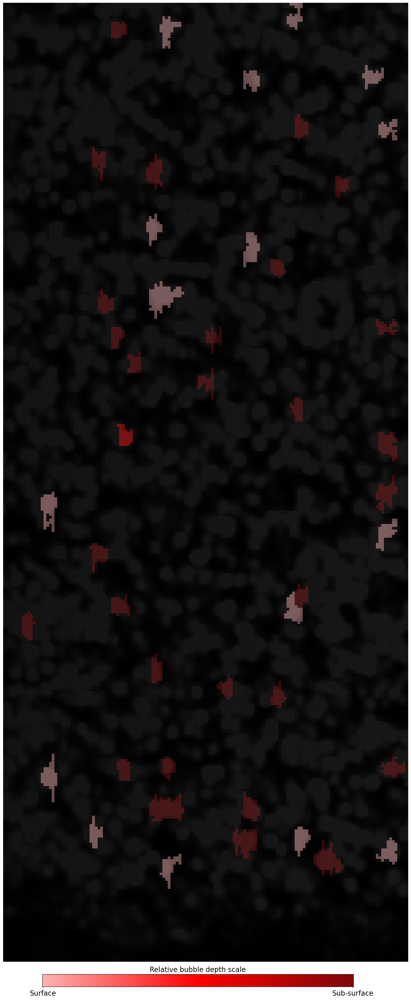

In [24]:
# from matplotlib.colors import LinearSegmentedColormap

# colors: [Light Red, Red, Dark Red]
custom_colors = [
    (1.0, 0.7, 0.7),   # light red
    (1.0, 0.0, 0.0),   # red
    (0.5, 0.027, 0.027)    # dark red
]

def to01(a, lo=None, hi=None):
    if lo is None or hi is None:
        lo, hi = np.nanpercentile(a, (1, 99))
        if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
            lo, hi = np.nanmin(a), np.nanmax(a)
    a = np.nan_to_num(a, nan=lo)
    out = (a - lo) / (hi - lo) if hi > lo else np.zeros_like(a, dtype=np.float32)
    return np.clip(out, 0, 1).astype(np.float32)

global_lo, global_hi = np.nanpercentile(correctedData, (1, 99))
n = correctedData.shape[2]
mid = n // 2
base = to01(correctedData[:, :, mid], global_lo, global_hi)

overlay = color.label2rgb(
    change_map, 
    image=base, 
    colors=custom_colors,
    bg_label=0,
    alpha=0.4,
    kind='overlay'
)

# ---- Plot ----
fig, ax = plt.subplots(figsize=(20, 40))
ax.imshow(overlay)
ax.axis('off')
#ax.set_title("Spatial Map of Bubble Size Change (.4µm vs 1µm)")
# ax.set_title("ALHIC1901-228_4", fontsize=16)

# ---- Add scale bar (gradient) ----
cmap = LinearSegmentedColormap.from_list("depth_red", custom_colors)

# Create a gradient image
gradient = np.linspace(0, 1, 256).reshape(1, -1)

# Add a small axis at the bottom
cbar_ax = fig.add_axes([0.25, 0.09, 0.5, 0.01])  # [left, bottom, width, height]
cbar_ax.imshow(gradient, aspect='auto', cmap=cmap)
cbar_ax.set_xticks([0, 255])
cbar_ax.set_xticklabels(["Surface", "Sub-surface"],fontsize=16)
cbar_ax.set_yticks([])
cbar_ax.set_title("Relative bubble depth scale", fontsize=16)

# ---- Save ----
out_path = f"{outputPath}/3dBubbles.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

In [19]:
# plt.figure(figsize=(10, 10), facecolor='black')
# # We use the 'short' coordinates for the position
# plt.scatter(plot_coords[:, 1], plot_coords[:, 0], 
#             s=plot_sizes, # Size of dot reflects size of bubble
#             c=colors, 
#             alpha=0.6, 
#             edgecolors='white', 
#             linewidth=0.5)

# plt.gca().invert_yaxis() # Match image coordinates
# plt.title("Bubble Size Comparison: 400nm (Short) vs 1000nm (Long)", color='white')
# plt.legend(handles=[
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='yellow', label='No Change'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='green', label='Bigger in 1000nm'),
#     plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', label='Smaller in 1000nm')
# ])
# plt.show()